## Question 1

### (a)
Trend is a scalar (-1,0,1). If the sum of trends i.e. Sv is same then phi(x) would also sum up to give the same result. E.g. if we have 3 neighbors with trends 0, 1, 0 and another node with 3 neighbors with trends -1, 1, 1. In both cases sum Sv would be 1 and phi(x) considering w=1, p=1 and c=1 would be:
for v1 (0,1,0) -> 1+2+1 = 4
for v2 (-1,1,1) -> 0+2+2 = 4

so the output is same when the number of neighbors Nv and sum of their trends Sv is the same. We can plug any value of p, c and w and the outputs would be same. 
Generic values would be:
$$ v1 (-1,1,1): p(c+w+c+c) = p(w+3c) $$
$$ v2 (-1,1,1): p(-w+c+w+c+w+c) = p(w+3c) $$

Thus, whatever values of w, p and c we plug in, result for both nodes will be same.

## (b)
Each node can have at most K neighbors such that 1<=Nv<=K where K is a known positive integer. To represent message in terms of K, we need a base that can retain the counts of different trends even after sum so they can be recovered. For this, if we assume K ranges from 0-9 then we would need base 10 to represent each trend as a separate place value of the sum. If we consider range 0-99, the base needed would be 100 and similarly, if the range is from 0-K (our situation where max number of neighbors is K) then base needed would be K+1. Now that our base is determined, we can represent the message value of each type of trend as:

$$ ϕ(0) = (K+1)^0 $$

$$ ϕ(1) = (K+1)^1 $$

$$ ϕ(-1) = (K+1)^2 $$

then Sum would be:

$$
S_v = \sum_{t \in \{-1,0,1\}} n_t \, \phi(t) \;=\; n_0 \cdot 1 \;+\; n_{+1}\,(K+1) \;+\; n_{-1}\,(K+1)^2
$$

For recovery, we will use the following rule:

$$
n_t = \left\lfloor \frac{M_v}{(K+1)^{p(t)}} \right\rfloor \bmod (K+1),
\qquad p(0)=0,\; p(+1)=1,\; p(-1)=2
$$

In [1]:
#Numpy Verification
import numpy as np
from itertools import product

K = 8
B = K + 1                      # base

# message per trend (one value per neighbour)
phi = {0: B**0, 1: B**1, -1: B**2}

# all triples (n_neg, n_zero, n_pos) with 1 <= total <= K
triples = np.array([t for t in product(range(K + 1), repeat=3)
                    if 1 <= sum(t) <= K])
n_neg, n_zero, n_pos = triples.T

# aggregated message: sum over trends of count * phi(trend)
M = n_neg * phi[-1] + n_zero * phi[0] + n_pos * phi[1]

# decoding rules 
dec_zero = M % B
dec_pos  = (M // B) % B
dec_neg  = (M // B**2) % B

# 1) decoding recovers every triple
assert np.array_equal(dec_neg,  n_neg)
assert np.array_equal(dec_zero, n_zero)
assert np.array_equal(dec_pos,  n_pos)

# 2) uniqueness: no two triples share a sum
assert len(np.unique(M)) == len(triples)

print(f"All {len(triples)} triples passed; max sum = {M.max()}")

All 164 triples passed; max sum = 648


###  (i) Count steady neighbours

**Sum**
Possible: Yes
Reason: Because counts of all trends can be recovered. first coordinate gives count of -1, second gives count of 0 and third gives count of 1. So we can easily get count of 0 from second coordinate. For example, for neighborhood (0,0,1,-1), aggregated vector is (1,2,1). Second coordinate gives us 2 which is the count of steady terms.

**Mean**
Possible: No
Reason: This gives contribution of each trend not the count and since total number of neighbors is not given so counts cannot be recovered. Considering 2 neighbors: (0, 0) and (0,0, 0) where both give aggregated vector: (0,1,0) even though counts of steady trend neighbors for both is different ( 2 vs 3).

**Max**
Possible: No
Reason: Counts cant be recovered because max only returns the max at each coordinate. Consider two neighborhoods: (0,0,-1,1,1) and (0,1,-1). Both have the same aggregated vector (1,1,1) even though the number of steady terms are different for both.

###  (ii) Decide whether more than half of the neighbours are slowing
**Sum**
Possible: Yes
Reason: Because counts can be recovered so we can see if more than half neighbors belong to slowing trend i.e. -1. For this, we just recover the count of slowing trend which is at first coordinate. We can divide this count by sum of all coordinates (essentially N_v) and if we get > 0.5 then more than half neighbors are slowing.

**Mean**
Possible: yes
Reason: Because contributions can be recovered. Get contribution of -1 from first index and if its > 0.5 then more than half neighbors are slowing

**Max**
Possible: No
Reason: Because counts/contributions cant be recovered. e.g. consider two neighborhoods: (-1,-1,-1,0,1) and (-1,0,1). Both give aggregated vector: (1,1,1) even though in first case, more than half the neighbors are slowing and in second case, that's not true.

###  (iii) Decide whether any neighbour is slowing
**Max**
Possible: Yes
Reason: Counts are recoverable so we can get count of slowing trend neighbors from first coordinate. If count > 0 then there are neighbors that are slowing.

**Max**
Possible: Yes
Reason: Contributions recoverable so if contribution of slowing trend neighbors i.e. value of first coordinate is > 0 then there are slowing neighbors.

**Max**
Possible: Yes 
Reason:  If the value of first coordinate = 1 then there is atleast one slowing neighbor in the neighborhood


## Question 2

#### a (ii)

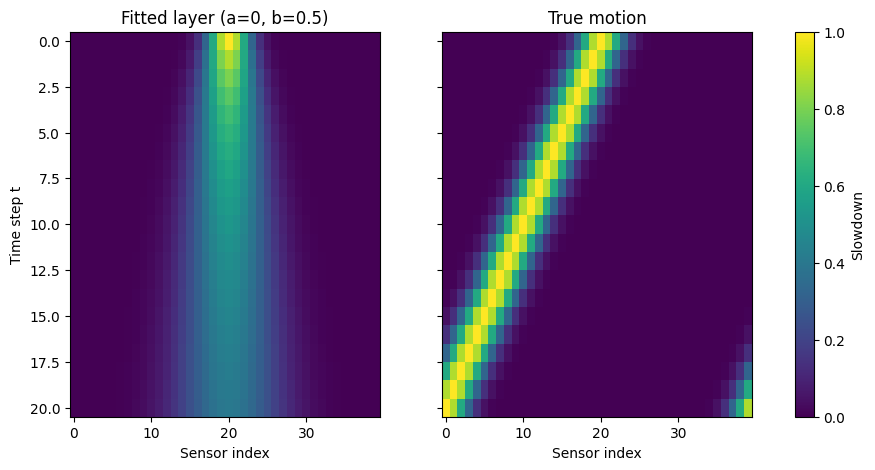

Peak height at t=20  fitted: 0.405  true: 1.0
Peak location at t=20 fitted: 20  true: 0


In [1]:
import numpy as np
import matplotlib.pyplot as plt

N, T = 40, 20
a, b = 0.0, 0.5

# initial smooth bump centred at sensor 20
i = np.arange(N)
x0 = np.exp(-(i - 20) ** 2 / 8)

# Sequence A: fitted layer, each prediction fed back in
A = np.zeros((T + 1, N))
A[0] = x0
for t in range(T):
    x = A[t]
    left, right = np.roll(x, 1), np.roll(x, -1)   # x_{i-1}, x_{i+1} (ring wraps)
    A[t + 1] = a * x + b * (left + right)

# Sequence B: true motion, shift one sensor against traffic per step
B = np.zeros((T + 1, N))
B[0] = x0
for t in range(T):
    B[t + 1] = np.roll(B[t], -1)                  # x_i(t+1) = x_{i+1}(t)

# heatmaps with a shared colour scale
vmin, vmax = 0, 1
fig, axes = plt.subplots(1, 2, figsize=(11, 5), sharey=True)
for ax, M, title in zip(axes, [A, B], ["Fitted layer (a=0, b=0.5)", "True motion"]):
    im = ax.imshow(M, aspect="auto", origin="upper", vmin=vmin, vmax=vmax,
                   cmap="viridis", extent=[-0.5, N - 0.5, T + 0.5, -0.5])
    ax.set_title(title)
    ax.set_xlabel("Sensor index")
axes[0].set_ylabel("Time step t")
fig.colorbar(im, ax=axes, label="Slowdown")
plt.show()

print("Peak height at t=20  fitted:", A[-1].max().round(3), " true:", B[-1].max().round(3))
print("Peak location at t=20 fitted:", A[-1].argmax(), " true:", B[-1].argmax())

### Comparison:
The sequence that uses fitted coefficients and gives equal weightage to both previous and next neighbor has sort of a flashilight shape where the slowdown's intensity decreased with each timestep and it is difficult to find out which direction it is moving. In the actual motion heatmap though, the intensity of slowdown remains same across time and the direction can easily be ascertained as moving backwards. 

#### c (iii)

Previous snapshot allows the model to see where the trend is moving or the movement direction. Depending on the pattern movement rule, the previous snapshot will show the direction to be moving backwards or forwards and that can help in predicting where the movement will be in the next step.

## Question 3
#### (a) Data Extraction and Resampling

In [3]:
import os, numpy as np, pandas as pd

# ---------- config ----------
IN_DIR  = "/kaggle/input/datasets/liuxu77/largest"      
OUT_DIR = "/kaggle/working/sd_15min"
YEARS   = [2020, 2021]
SD_DISTRICT = 11
AGG = "sum"    # cause counts in data
os.makedirs(OUT_DIR, exist_ok=True)


In [4]:
# ---------- SD sensors and adjacency ----------
meta = pd.read_csv(f"{IN_DIR}/ca_meta.csv")     # adjust name if needed
print(meta.head())                              # check the ID / District columns
sd_mask = (meta["District"] == SD_DISTRICT).values
sd_idx  = np.where(sd_mask)[0]
sd_ids  = meta.loc[sd_mask, "ID"].astype(str).values
assert len(sd_ids) == 716, len(sd_ids)

adj_ca = np.load(f"{IN_DIR}/ca_rn_adj.npy")     # adjust name if needed
assert adj_ca.shape[0] == len(meta)             # rows follow the metadata order
adj_sd = adj_ca[np.ix_(sd_idx, sd_idx)]
np.save(f"{OUT_DIR}/sd_adj.npy", adj_sd)
np.save(f"{OUT_DIR}/sd_ids.npy", sd_ids)

       ID        Lat         Lng  District      County   Fwy  Lanes      Type  \
0  317802  38.389811 -121.479587         3  Sacramento  I5-N      2  Mainline   
1  312134  38.412564 -121.484319         3  Sacramento  I5-N      2  Mainline   
2  312133  38.428630 -121.487657         3  Sacramento  I5-N      3  Mainline   
3  313159  38.450246 -121.492176         3  Sacramento  I5-N      3  Mainline   
4  319767  38.465539 -121.496450         3  Sacramento  I5-N      3  Mainline   

  Direction  ID2  
0         N    0  
1         N    1  
2         N    2  
3         N    3  
4         N    4  


In [5]:
# ---------- load one year at a time, keep only SD columns ----------
def load_year(y):
    df = pd.read_hdf(f"{IN_DIR}/ca_his_raw_{y}.h5")
    df.columns = df.columns.astype(str)
    df = df[sd_ids].astype("float32")           # select by ID so the order matches sd_ids
    return df

           # expected (~70k, 716)

2020 5-min shape: (105408, 716) | duplicate timestamps: 0
2021 5-min shape: (105120, 716) | duplicate timestamps: 0
15-min shape: (70176, 716)


In [11]:
x

Time                        
2021-01-01 00:00:00  1114091    49.0
                     1118333    25.0
                     1118348    16.0
                     1114720    11.0
                     1118352    12.0
                                ... 
2021-12-31 23:55:00  1114296    48.0
                     1118544    39.0
                     1108719    42.0
                     1122536    67.0
                     1118170    16.0
Length: 4939560, dtype: float32

In [12]:
## to make decusion for agg
df5_2021 = load_year(2021)
x = df5_2021[sd_ids[:50]].stack().dropna()      # sample from one year's 5-min data
print("integer-valued:", np.mean(x == np.round(x)))
print("multiples of 12:", np.mean((x % 12) == 0))

integer-valued: 1.0
multiples of 12: 0.08338435002307898


In [ ]:
def to_15min(df5):
    full = pd.date_range(df5.index.min().floor("D"),
                         df5.index.max().ceil("D") - pd.Timedelta("5min"), freq="5min")
    df5 = df5.reindex(full)                     # exposes missing timestamps as NaN
    r = df5.resample("15min")
    out = r.sum(min_count=3) if AGG == "sum" else r.mean()   # incomplete bins -> NaN for sum
    return out

parts = []
for y in YEARS:
    df5 = load_year(y)
    print(y, "5-min shape:", df5.shape, "| duplicate timestamps:", df5.index.duplicated().sum())
    parts.append(to_15min(df5))
    del df5
df15 = pd.concat(parts)
assert df15.index.is_monotonic_increasing and not df15.index.duplicated().any()
print("15-min shape:", df15.shape) 

In [6]:
# ---------- missing-value diagnostics (for Q3(a) item 4) ----------
nan_frac_total  = df15.isna().mean().mean()
nan_frac_sensor = df15.isna().mean()
zero_frac       = (df15 == 0).mean().mean()
print(f"NaN fraction overall: {nan_frac_total:.4f}")
print(f"Zero fraction overall: {zero_frac:.4f}")
print("Sensors with >20% NaN:", (nan_frac_sensor > 0.2).sum(),
      "| fully missing:", (nan_frac_sensor == 1).sum())
print(df15.isna().groupby(df15.index.year).mean().mean(axis=1))   # per year

NaN fraction overall: 0.0508
Zero fraction overall: 0.0014
Sensors with >20% NaN: 44 | fully missing: 19
2020    0.041127
2021    0.060411
dtype: float64


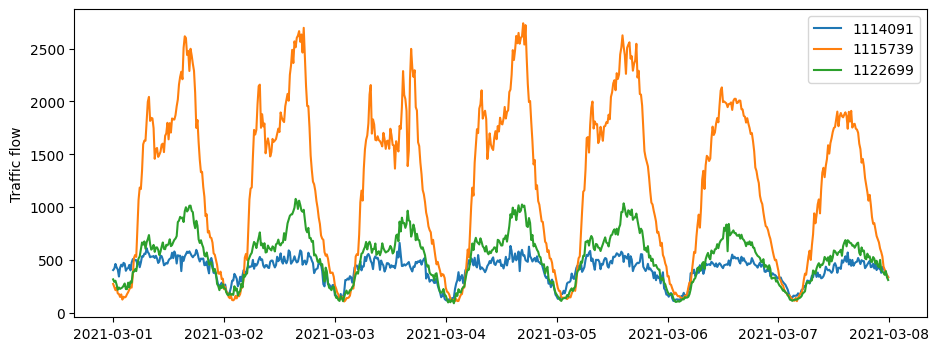

In [7]:
# ---------- save (raw, NaNs kept, plus mask) ----------
flow  = df15.values.astype("float32")           # (T, 716)
mask  = ~np.isnan(flow)
np.save(f"{OUT_DIR}/flow_15min.npy", flow)
np.save(f"{OUT_DIR}/mask.npy", mask)
np.save(f"{OUT_DIR}/timestamps.npy", df15.index.values)

# ---------- one-week plot for three sensors (item 5) ----------
import matplotlib.pyplot as plt
week = df15.loc["2021-03-01":"2021-03-07"]
fig, ax = plt.subplots(figsize=(11, 4))
for s in week.columns[[0, 300, 600]]:
    ax.plot(week.index, week[s], label=s)
ax.set_ylabel("Traffic flow"); ax.legend(); plt.show()

In [14]:
from IPython.display import FileLink

# Replace 'filename.ext' with your actual file name
FileLink('/kaggle/working/sd_15min/flow_15min.npy')


/kaggle/working/sd_15min/flow_15min.npy